# Checkpoint visualizations
These are the two charts for the check-point meeting, built from the tables `01_data_prep.ipynb` writes. Each is saved to `figures/` as an interactive `.html` and a static `.png`.

1. **Median song length by year, hits vs. all music** (plan viz #1, interactive)
2. **Change in median length by genre family × year** (plan viz #2, static heatmap)

Both charts stop at **2022** because 2023 is a partial year in both sources. The Spotify scrape ended in June 2023, and only about 25% of 2023 Hot 100 debuts matched.

In [1]:
# installs the two chart libraries if they're missing (quick no-op if already installed)
%pip install -q altair vl-convert-python

In [2]:
import os
import pandas as pd
import altair as alt
from IPython.display import Image, display

PROC, FIG = "data/processed", "figures"
os.makedirs(FIG, exist_ok=True)
LAST_YEAR = 2022

# shared style: used by every chart in the project so the site looks consistent
INK, INK2, MUTED, GRID, AXIS, SURFACE = "#0b0b0b", "#52514e", "#898781", "#e1e0d9", "#c3c2b7", "#fcfcfb"
HITS_COLOR, ALL_COLOR = "#2a78d6", "#eb6834"          # blue = Hot 100 hits, orange = all Spotify tracks
SHORTER, LONGER, NEUTRAL = "#d03b3b", "#256abf", "#f0efec"

def theme():
    font = "system-ui, -apple-system, Segoe UI, sans-serif"
    return {"config": {
        "background": SURFACE, "font": font,
        "view": {"stroke": None},
        "title": {"color": INK, "fontSize": 16, "fontWeight": 600, "anchor": "start",
                  "subtitleColor": INK2, "subtitleFontSize": 12, "offset": 12},
        "axis": {"labelColor": INK2, "titleColor": INK2, "gridColor": GRID, "domainColor": AXIS,
                 "tickColor": AXIS, "labelFontSize": 11, "titleFontSize": 12, "titleFontWeight": 500},
        "legend": {"labelColor": INK2, "titleColor": INK2, "labelFontSize": 11, "titleFontSize": 11},
    }}
if hasattr(alt, "theme"):                 # Altair >= 5.5
    alt.theme.register("ds4200", enable=True)(theme)
else:                                      # older Altair
    alt.themes.register("ds4200", theme); alt.themes.enable("ds4200")

def save_and_show(chart, name):
    """save interactive HTML + static PNG; show the PNG inline (always renders) and the live chart"""
    chart.save(f"{FIG}/{name}.html")
    try:
        chart.save(f"{FIG}/{name}.png", scale_factor=2)
        display(Image(f"{FIG}/{name}.png", width=760))
    except Exception as e:
        print("PNG export skipped (pip install vl-convert-python):", e)
    return chart

def mmss(minutes):
    s = int(round(minutes * 60))
    return f"{s // 60}:{s % 60:02d}"

hits = pd.read_csv(f"{PROC}/hits_clean.csv")
all_music = pd.read_csv(f"{PROC}/all_music_yearly.csv")
genre_yearly = pd.read_csv(f"{PROC}/genre_family_yearly.csv")

## Chart 1: Are songs getting shorter, and do hits differ from music overall?
Each line is the yearly median length. The shaded band is the middle 50% of songs (25th to 75th percentile), so the chart shows whether the whole distribution moved and not just the average.
Hits use matched Hot 100 songs grouped by debut year. "All music" uses every track in the Spotify file.

**Interaction:** hover a point for exact values. Click a legend entry to highlight that series.

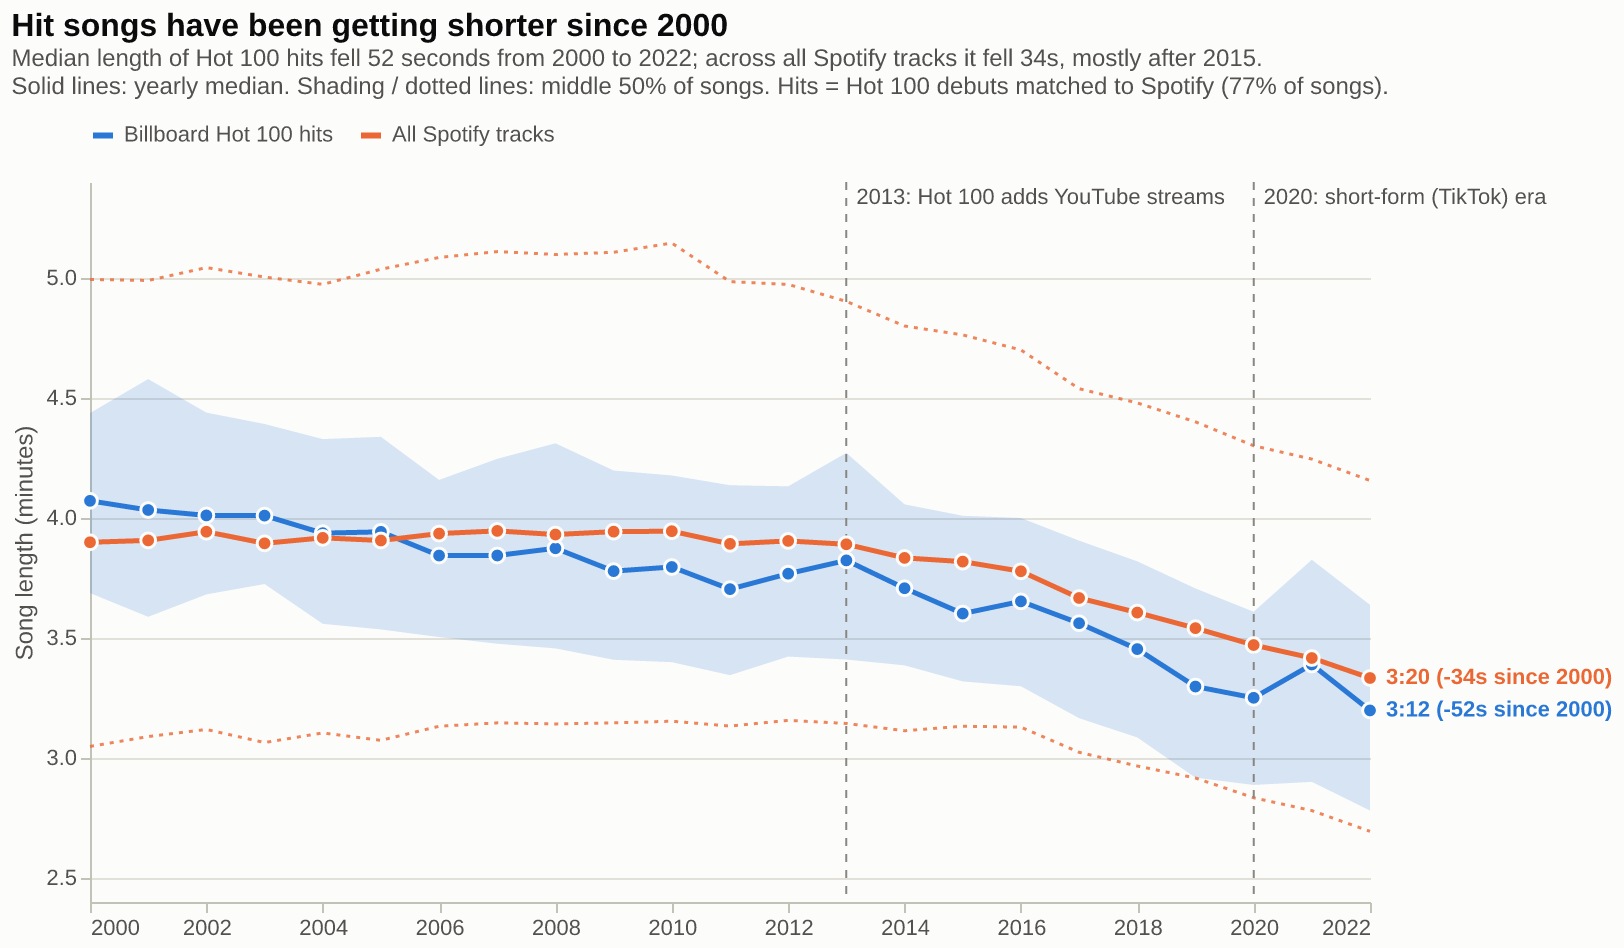

alt.LayerChart(...)

In [3]:
h = hits[hits.matched & (hits.debut_year <= LAST_YEAR)]
hit_yearly = (h.groupby("debut_year").duration_min
                .agg(median="median", q25=lambda s: s.quantile(.25), q75=lambda s: s.quantile(.75), n="size")
                .reset_index().rename(columns={"debut_year": "year"}))
hit_yearly["series"] = "Billboard Hot 100 hits"
am = all_music[all_music.year <= LAST_YEAR].rename(columns={"n_tracks": "n"})
am["series"] = "All Spotify tracks"
trend = pd.concat([hit_yearly, am[hit_yearly.columns]], ignore_index=True)
for c in ["median", "q25", "q75"]:
    trend[c + "_label"] = trend[c].map(mmss)

order = ["Billboard Hot 100 hits", "All Spotify tracks"]
series_scale = alt.Scale(domain=order, range=[HITS_COLOR, ALL_COLOR])
color = alt.Color("series:N", title=None, sort=order, scale=series_scale,
                  legend=alt.Legend(orient="top", direction="horizontal", symbolType="stroke",
                                    symbolStrokeWidth=3, symbolOpacity=1))
pick = alt.selection_point(fields=["series"], bind="legend")
x = alt.X("year:Q", title=None, scale=alt.Scale(domain=[2000, LAST_YEAR], nice=False),
          axis=alt.Axis(format="d", values=list(range(2000, LAST_YEAR + 1, 2)), grid=False))
y_title = "Song length (minutes)"

base = alt.Chart(trend).encode(x=x, color=color)
y_scale = alt.Scale(domain=[2.5, 5.25], zero=False)
# hits: filled band; all music: dotted edges, so the two bands don't blend into one muddy area
band = (alt.Chart(trend[trend.series == order[0]]).encode(x=x, color=color)
        .mark_area(opacity=0.18).encode(
            y=alt.Y("q25:Q", title=y_title, scale=y_scale), y2="q75:Q",
            opacity=alt.condition(pick, alt.value(0.18), alt.value(0.03))))
edges = (alt.Chart(trend[trend.series == order[1]]).transform_fold(["q25", "q75"], as_=["bound", "value"])
         .mark_line(strokeDash=[2, 3], strokeWidth=1.5)
         .encode(x=x, y=alt.Y("value:Q", scale=y_scale), detail="bound:N", color=color,
                 opacity=alt.condition(pick, alt.value(0.8), alt.value(0.1))))
line = base.mark_line(strokeWidth=2.5).encode(
    y="median:Q",
    opacity=alt.condition(pick, alt.value(1), alt.value(0.15)))
tooltip = [alt.Tooltip("series:N", title="Series"), alt.Tooltip("year:Q", title="Year", format="d"),
           alt.Tooltip("median_label:N", title="Median length"),
           alt.Tooltip("q25_label:N", title="25th percentile"),
           alt.Tooltip("q75_label:N", title="75th percentile"),
           alt.Tooltip("n:Q", title="Songs", format=",")]
points = base.mark_circle(size=55, stroke=SURFACE, strokeWidth=1.5).encode(
    y="median:Q", tooltip=tooltip,
    opacity=alt.condition(pick, alt.value(1), alt.value(0.15)))

markers = pd.DataFrame({"year": [2013, 2020],
                        "label": ["2013: Hot 100 adds YouTube streams", "2020: short-form (TikTok) era"]})
rules = alt.Chart(markers).mark_rule(color=MUTED, strokeDash=[4, 4]).encode(x="year:Q")
rule_text = alt.Chart(markers).mark_text(align="left", dx=5, dy=-2, baseline="top", color=INK2, fontSize=11
                                         ).encode(x="year:Q", y=alt.value(4), text="label:N")

# direct labels at the right end of each line, carrying the overall change
first, last = trend[trend.year == 2000].set_index("series"), trend[trend.year == LAST_YEAR].set_index("series")
ends = last.reset_index()
ends["end_label"] = [f"{mmss(last.loc[s,'median'])}  ({(last.loc[s,'median']-first.loc[s,'median'])*60:+.0f}s since 2000)"
                     for s in ends.series]
end_text = alt.Chart(ends).mark_text(align="left", dx=8, fontSize=11, fontWeight=600).encode(
    x="year:Q", y="median:Q", text="end_label:N", color=alt.Color("series:N", scale=series_scale, legend=None))

hd, ad = (first.loc[s, "median"] - last.loc[s, "median"] for s in order)
chart1 = (alt.layer(band, edges, rules, line, points, rule_text, end_text)
          .add_params(pick)
          .properties(width=640, height=360,
                      title=alt.Title("Hit songs have been getting shorter since 2000",
                                      subtitle=[f"Median length of Hot 100 hits fell {hd*60:.0f} seconds from 2000 to {LAST_YEAR}; "
                                                f"across all Spotify tracks it fell {ad*60:.0f}s, mostly after 2015.",
                                                "Solid lines: yearly median. Shading / dotted lines: middle 50% of songs. Hits = Hot 100 debuts matched to Spotify (77% of songs)."]))
          .configure_view(stroke=None))
save_and_show(chart1, "chart1_length_trend")

**Takeaway:** hits have been shrinking steadily since 2000, roughly 50 seconds by 2022. Music overall held near 3:55 until about 2015 and then fell. The middle-50% bands move down together, so the whole distribution shifted and the change isn't just a few long outliers disappearing.
For the streaming question, the catalog's break comes in the streaming years, but hits were already getting shorter in the 2000s.

## Chart 2: Is the shortening happening in every genre?
Each cell is a genre family's median track length in one year, compared with that family's own 2000–02 median. Red means shorter, blue means longer.
Measuring each family against its own baseline keeps naturally long genres (electronic) from swamping naturally short ones (punk inside rock).
The data is the full Spotify file, about 2,000–20,000 tracks per cell. Hits are too sparse for some families (24 matched Latin hits in total).

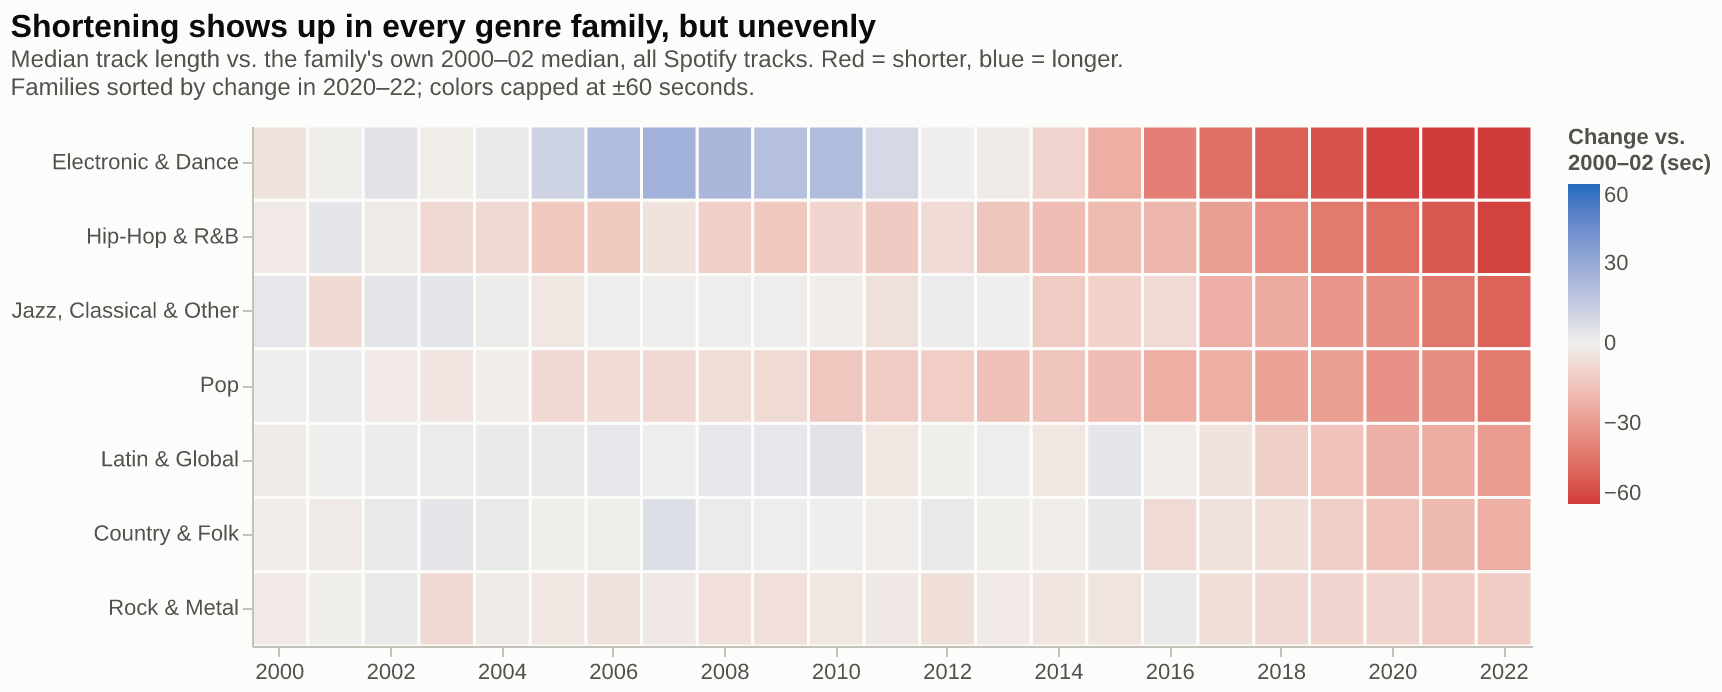

alt.Chart(...)

In [4]:
g = genre_yearly[genre_yearly.year <= LAST_YEAR].copy()
base_len = g[g.year <= 2002].groupby("genre_family")["median"].mean()
g["baseline"] = g.genre_family.map(base_len)
g["change_sec"] = (g["median"] - g["baseline"]) * 60
g["median_label"] = g["median"].map(mmss)
g["baseline_label"] = g["baseline"].map(mmss)
row_order = (g[g.year >= LAST_YEAR - 2].groupby("genre_family").change_sec.mean()
               .sort_values().index.tolist())                    # most-shortened family on top
lim = 60
chart2 = (alt.Chart(g).mark_rect(stroke=SURFACE, strokeWidth=1.5).encode(
            x=alt.X("year:O", title=None, axis=alt.Axis(labelAngle=0, values=list(range(2000, LAST_YEAR + 1, 2)))),
            y=alt.Y("genre_family:N", title=None, sort=row_order),
            color=alt.Color("change_sec:Q", title=["Change vs.", "2000–02 (sec)"],
                            scale=alt.Scale(domain=[-lim, 0, lim], range=[SHORTER, NEUTRAL, LONGER], clamp=True, interpolate="lab"),
                            legend=alt.Legend(gradientLength=160, values=[-60, -30, 0, 30, 60])),
            tooltip=[alt.Tooltip("genre_family:N", title="Genre family"), alt.Tooltip("year:O", title="Year"),
                     alt.Tooltip("median_label:N", title="Median length"),
                     alt.Tooltip("baseline_label:N", title="2000–02 median"),
                     alt.Tooltip("change_sec:Q", title="Change (sec)", format="+.0f"),
                     alt.Tooltip("n_tracks:Q", title="Tracks", format=",")])
          .properties(width=640, height=260,
                      title=alt.Title("Shortening shows up in every genre family, but unevenly",
                                      subtitle=["Median track length vs. the family's own 2000–02 median, all Spotify tracks. "
                                                "Red = shorter, blue = longer.",
                                                "Families sorted by change in 2020–22; colors capped at ±60 seconds."]))
          .configure_view(stroke=None))
save_and_show(chart2, "chart2_genre_heatmap")

**Takeaway:** every family is shorter in 2020–22 than in 2000–02, but by very different amounts and at different times.
Electronic & Dance actually got *longer* in the mid-2000s, then fell more than a minute. Hip-Hop & R&B and Pop drift down from about 2014–15, the early streaming years. Rock & Metal barely moved (−12s).
The streaming hypothesis predicts the biggest drops in stream-heavy genres after 2012, and this is broadly consistent with it. The Jazz/Classical decline is a caution: it suggests part of the drop could come from how the Spotify sample was collected.

In [5]:
summary = (g[g.year >= LAST_YEAR - 2].groupby("genre_family")
             .agg(baseline=("baseline_label", "first"), median_2020_22=("median", "mean"), change_sec=("change_sec", "mean")))
summary["median_2020_22"] = summary.median_2020_22.map(mmss)
summary.round(0).sort_values("change_sec")

,baseline,median_2020_22,change_sec
genre_family,,,
Electronic & Dance,4:38,3:35,-64.0
Hip-Hop & R&B,4:14,3:23,-52.0
"Jazz, Classical & Other",3:50,3:08,-42.0
Pop,4:04,3:28,-36.0
Latin & Global,3:40,3:15,-25.0
Country & Folk,3:40,3:20,-19.0
Rock & Metal,3:44,3:32,-12.0
